# Chance and lift: do two items meet more often than chance?

**Week 4, Wednesday, chapter 3 of the concept block.** The topic, in the curriculum's words: *Support, confidence and lift, derived by counting*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** The canteen manager, who wants pairs that sell together more than they would anyway; a pair that merely meets as often as chance puts nothing extra on the counter.

**The questions on the way.** What would chance give? What is lift? Does lift have a direction? What does lift not say?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
listed = lines.groupby("order_id").item.apply(list)      # the items in the order the bill lists them
baskets = listed.apply(set)                               # one set of items per order
n = len(baskets)
print("A hostel canteen's twelve lunch orders, invented for the concept chapters:")
for order_id, held in listed.items():
    print(f"  {order_id}: {', '.join(held)}")


def has(item):
    """True for every order that holds the item."""
    return baskets.apply(lambda b: item in b)


check("twelve orders and 33 order lines", n == 12 and len(lines) == 33)

A hostel canteen's twelve lunch orders, invented for the concept chapters:
  T01: dal rice, papad, chaas
  T02: dal rice, papad, chaas
  T03: dal rice, papad, chaas
  T04: dal rice, sabzi, chaas
  T05: dal rice, chaas
  T06: dal rice, curd, chaas
  T07: roti, papad, pickle
  T08: papad, pickle
  T09: roti, sabzi, chaas
  T10: roti, sabzi, chaas
  T11: roti, sabzi, chaas
  T12: gulab jamun, curd
PASS twelve orders and 33 order lines


## If roti and sabzi ignored each other, how many orders would hold both?

Week 1 Thursday built a chance reference, the number a count would show if nothing were
going on. Here it takes one multiplication. If roti and sabzi ignored each other, roti's
orders would hold sabzi at the rate all orders do.

**Predict before you run.** Roti is in 4 of 12 orders and sabzi in 4. By chance alone, how
many orders hold both?

a) 0, since items that ignore each other never meet.
b) 1.33, a third of roti's 4 orders, if sabzi ignored roti.
c) 3, since three orders hold both on the cards.
d) 4, since that is roti's own count.

In [2]:
roti, sabzi = has("roti"), has("sabzi")
chance = n * (roti.sum() / n) * (sabzi.sum() / n)
seen = (roti & sabzi).sum()
print(f"chance alone: {n} x {roti.sum()}/{n} x {sabzi.sum()}/{n} = {chance:.2f} orders")
print(f"seen: {seen} orders, so lift = {seen} / {chance:.2f} = {seen / chance:.2f}")
check("chance gives roti and sabzi 1.33 orders", round(chance, 2) == 1.33)
check("lift of roti and sabzi is 2.25", round(seen / chance, 2) == 2.25)

chance alone: 12 x 4/12 x 4/12 = 1.33 orders
seen: 3 orders, so lift = 3 / 1.33 = 2.25
PASS chance gives roti and sabzi 1.33 orders
PASS lift of roti and sabzi is 2.25


**What happened.** The answer is b. Chance alone gives
12 x 4/12 x 4/12 = 1.33 orders; three are seen, so
**lift**, the seen count over the chance count, is 3 / 1.33 =
2.25. Two misconceptions fall here: "expected" means what
chance alone gives, never what anyone hopes to see, and two items that ignore each other
still share baskets at their own rates. The picture puts seen beside chance for four pairs.

roti + sabzi: seen 3, chance 1.33, lift 2.25
dal rice + papad: seen 3, chance 2.50, lift 1.20
roti + chaas: seen 3, chance 3.00, lift 1.00
papad + chaas: seen 3, chance 3.75, lift 0.80


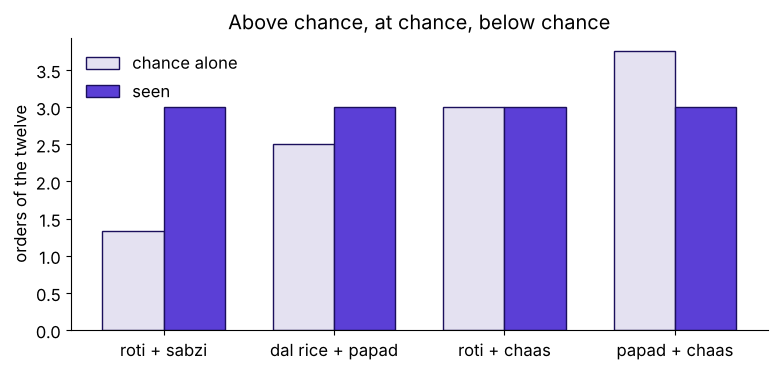

PASS roti and chaas sit exactly at chance


In [3]:
four = [("roti", "sabzi"), ("dal rice", "papad"), ("roti", "chaas"), ("papad", "chaas")]
rows = []
for a, b in four:
    ha, hb = has(a), has(b)
    rows.append((f"{a} + {b}", (ha & hb).sum(), n * (ha.sum() / n) * (hb.sum() / n)))
for name, k, e in rows:
    print(f"{name}: seen {k}, chance {e:.2f}, lift {k / e:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(rows))
ax.bar([i - 0.18 for i in x], [e for _, _, e in rows], 0.36, color="#E4E1F1", edgecolor="#1A0F5C", label="chance alone")
ax.bar([i + 0.18 for i in x], [k for _, k, _ in rows], 0.36, color="#5B3FD6", edgecolor="#1A0F5C", label="seen")
ax.set_xticks(list(x), [name for name, _, _ in rows])
ax.set_ylabel("orders of the twelve")
ax.legend(frameon=False)
ax.set_title("Above chance, at chance, below chance")
plt.show()
check("roti and chaas sit exactly at chance", rows[2][1] == rows[2][2])

## Why does lift read the same from both sides?

The formula, named last: lift = seen / chance = both x all / (A x B) =
3 x 12 / (4 x 4) = 2.25. Divided through, lift is also
confidence over the partner's share: from roti, 0.75 / (4/12); from sabzi, the same, which
is why lift has no direction. The picture draws it as two areas on a unit square: roti's
band times sabzi's band is the box chance gives, and the seen box is taller.

chance area 0.11, seen area 0.25, lift 2.25
second route: from roti 2.25, from sabzi 2.25


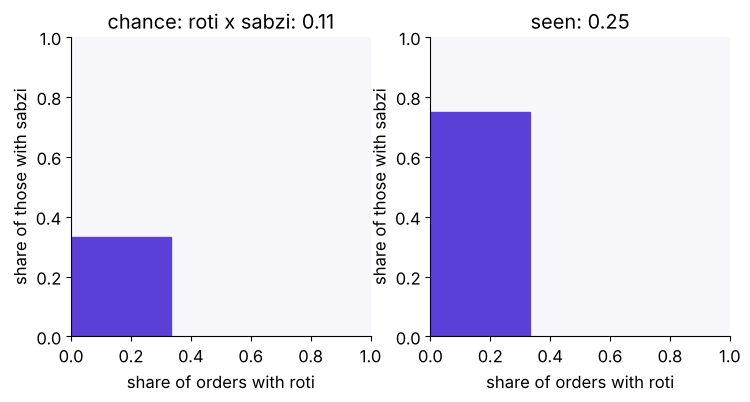

PASS the second route gives 2.25 from either side


In [4]:
a_share, b_share = roti.mean(), sabzi.mean()
seen_share = (roti & sabzi).mean()
from_roti = seen_share / a_share / b_share
from_sabzi = seen_share / b_share / a_share
print(f"chance area {a_share * b_share:.2f}, seen area {seen_share:.2f}, lift {seen_share / (a_share * b_share):.2f}")
print(f"second route: from roti {from_roti:.2f}, from sabzi {from_sabzi:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4))
for ax, height, title in [(axes[0], b_share, "chance: roti x sabzi"), (axes[1], seen_share / a_share, "seen")]:
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="#F7F6FB"))
    ax.add_patch(plt.Rectangle((0, 0), a_share, height, color="#5B3FD6"))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("share of orders with roti")
    ax.set_ylabel("share of those with sabzi")
    ax.set_title(f"{title}: {a_share * height:.2f}")
plt.show()
check("the second route gives 2.25 from either side", round(from_roti, 2) == round(from_sabzi, 2) == 2.25)

## What does lift say about every pair of the twelve orders?

Lift below one means together less often than chance, exactly one means chance, and
above one more often. The cell computes it three ways for all 13 pairs and checks that
the three agree: seen over chance, confidence from the first over the second's share, and
confidence from the second over the first's share. Sabzi and chaas are left out of the
printout, since they are the your-turn pair below.

curd + gulab jamun: lift 6.00 on 1 order
papad + pickle: lift 2.40 on 2 orders
roti + sabzi: lift 2.25 on 3 orders
pickle + roti: lift 1.50 on 1 order
chaas + dal rice: lift 1.33 on 6 orders
dal rice + papad: lift 1.20 on 3 orders
chaas + roti: lift 1.00 on 3 orders
curd + dal rice: lift 1.00 on 1 order
chaas + papad: lift 0.80 on 3 orders
chaas + curd: lift 0.67 on 1 order
papad + roti: lift 0.60 on 1 order
dal rice + sabzi: lift 0.50 on 1 order


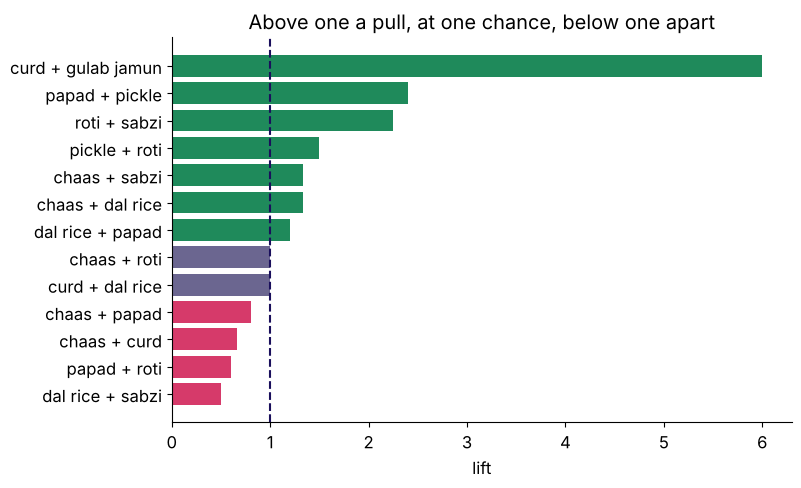

PASS the three routes to lift agree for every pair


In [5]:
single = Counter(x for b in baskets for x in b)
pair_count = Counter(p for b in baskets for p in combinations(sorted(b), 2))
lifts = []
agree = True
for (a, b), k in pair_count.items():
    one = k * n / (single[a] * single[b])
    two = (k / single[a]) / (single[b] / n)
    three = (k / single[b]) / (single[a] / n)
    agree = agree and abs(one - two) < 1e-9 and abs(one - three) < 1e-9
    lifts.append((f"{a} + {b}", k, one))
lifts.sort(key=lambda r: r[2])
for name, k, lift in lifts[::-1]:
    if name != "chaas + sabzi":
        print(f"{name}: lift {lift:.2f} on {k} order{'s' if k > 1 else ''}")
fig, ax = plt.subplots(figsize=(8, 5))
colours = ["#1F8A5B" if l > 1.001 else ("#6B6690" if l > 0.999 else "#D63A6A") for _, _, l in lifts]
ax.barh([name for name, _, _ in lifts], [l for _, _, l in lifts], color=colours)
ax.axvline(1, color="#1A0F5C", ls="--")
ax.set_xlabel("lift")
ax.set_title("Above one a pull, at one chance, below one apart")
plt.show()
check("the three routes to lift agree for every pair", agree)

### Your turn: what do chance and lift give sabzi and chaas?

Sabzi is in 4 orders, chaas in 9, both in 4. In the empty cell below, compute the count
chance alone gives the pair and its lift, and store them as `sabzi_chaas_chance` and
`sabzi_chaas_lift`. Then run the check under it.

In [6]:
mine = (globals().get("sabzi_chaas_chance"), globals().get("sabzi_chaas_lift"))
if None in mine:
    print("Store your answers as sabzi_chaas_chance and sabzi_chaas_lift in the empty cell above, then run this cell again.")
else:
    ref_chance = n * has("sabzi").mean() * has("chaas").mean()
    ref_lift = (has("sabzi") & has("chaas")).sum() / ref_chance
    print(f"reference: chance {ref_chance:.2f} orders, lift {ref_lift:.2f}")
    ok = abs(mine[0] - ref_chance) <= 0.005 and abs(mine[1] - ref_lift) <= 0.005
    print("both match at two decimals" if ok else "not yet: total x share x share, then seen over chance")

Store your answers as sabzi_chaas_chance and sabzi_chaas_lift in the empty cell above, then run this cell again.


## What should you keep from chapter 3?

- Chance alone gives a pair all baskets times A's share times B's share.
- Lift is the seen count over the chance count, and it reads the same from both sides.
- Lift below one means together less often than chance, near one means chance, above one
  a pull: roti and chaas sit exactly at 1.00.
- Lift 2.25 never means roti makes anyone buy more sabzi.
  Only a change at the counter, tested fairly, shows cause, which is the subject of this
  week's Monday faculty session on A/B testing (tentative).

**In the interview.** "Which of the three counts cannot be fooled by popularity?" Lift,
because it divides by the partner's share; notebook 04 shows the trap it avoids, and
chapters 7 and 8 read lift on Instamart's carts.